In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [2]:
# === Step 1: Paths ===
train_dir = r"G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\train\spiral"
val_dir = r"G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\valid\spiral"
test_dir = r"G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\test\spiral"

# === Step 2: Parameters ===
batch_size = 32
img_size = (224, 224)
epochs = 30

In [3]:
# Cell 3: Data generators (force RGB mode)
# === Step 3: Data Augmentation ===
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)
val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

Found 3640 images belonging to 2 classes.
Found 200 images belonging to 2 classes.


In [4]:
# Cell 4: Build model (binary classification)
# === Step 4: Build Model ===
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(2, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# Unfreeze all layers for fine-tuning
for layer in base_model.layers:
    layer.trainable = True

# === Step 5: Compile Model ===
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1 (Conv2D)                │ (None, 112, 112, 32)      │             864 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_Conv1 (BatchNormalization) │ (None, 112, 112, 32)      │             128 │ Conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1_relu (ReLU)             │ (None, 112, 112, 32)      │               0 │ bn_Conv1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise       │ (None, 112, 112, 32)      │             288 │ Conv1_relu[0][0]           │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_BN    │ (None, 112, 112, 32)      │             128 │ expanded_conv_depthwise[0… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_relu  │ (None, 112, 112, 32)      │               0 │ expanded_conv_depthwise_B… │
│ (ReLU)                        │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project         │ (None, 112, 112, 16)      │             512 │ expanded_conv_depthwise_r… │
│ (Conv2D)                      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project_BN      │ (None, 112, 112, 16)      │              64 │ expanded_conv_project[0][… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand (Conv2D)       │ (None, 112, 112, 96)      │           1,536 │ expanded_conv_project_BN[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_BN             │ (None, 112, 112, 96)      │             384 │ block_1_expand[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_relu (ReLU)    │ (None, 112, 112, 96)      │               0 │ block_1_expand_BN[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_pad (ZeroPadding2D)   │ (None, 113, 113, 96)      │               0 │ block_1_expand_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_depthwise             │ (None, 56, 56, 96)        │             864 │ block_1_pad[0][0]          │
│ (DepthwiseConv2D)             │                           │               

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,226,434 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [5]:
# Cell 5: Callbacks and Training
# === Step 6: Callbacks ===
checkpoint = ModelCheckpoint("F1_spiral_mobilenetv2_finetuned.h5", monitor="val_accuracy", save_best_only=True, verbose=1)
earlystop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, min_lr=1e-6, verbose=1)

# === Step 7: Train ===
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=epochs,
    callbacks=[checkpoint, earlystop, reduce_lr]
)


C:\Users\Python1\anaconda3\envs\vtpml04_2\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7584 - loss: 0.4985
Epoch 1: val_accuracy improved from -inf to 0.52500, saving model to F1_spiral_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 447s 4s/step - accuracy: 0.7592 - loss: 0.4972 - val_accuracy: 0.5250 - val_loss: 1.7186 - learning_rate: 1.0000e-04
Epoch 2/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9396 - loss: 0.1569
Epoch 2: val_accuracy improved from 0.52500 to 0.55000, saving model to F1_spiral_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 373s 3s/step - accuracy: 0.9397 - loss: 0.1567 - val_accuracy: 0.5500 - val_loss: 3.1832 - learning_rate: 1.0000e-04
Epoch 3/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9726 - loss: 0.0726
Epoch 3: val_accuracy improved from 0.55000 to 0.57500, saving model to F1_spiral_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 343s 3s/step - accuracy: 0.9726 - loss: 0.0725 - val_accuracy: 0.5750 - val_loss: 2.9869 - learning_rate: 1.0000e-04
Epoch 4/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9671 - loss: 0.0917
Epoch 4: val_accuracy improved from 0.57500 to 0.74000, saving model to F1_spiral_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 360s 3s/step - accuracy: 0.9671 - loss: 0.0915 - val_accuracy: 0.7400 - val_loss: 1.4535 - learning_rate: 1.0000e-04
Epoch 5/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9854 - loss: 0.0460
Epoch 5: val_accuracy did not improve from 0.74000
114/114 ━━━━━━━━━━━━━━━━━━━━ 339s 3s/step - accuracy: 0.9854 - loss: 0.0459 - val_accuracy: 0.6750 - val_loss: 3.4088 - learning_rate: 1.0000e-04
Epoch 6/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9912 - loss: 0.0236
Epoch 6: val_accuracy did not improve from 0.74000
114/114 ━━━━━━━━━━━━━━━━━━━━ 345s 3s/step - accuracy: 0.9912 - loss: 0.0236 - val_accuracy: 0.6350 - val_loss: 3.5659 - learning_rate: 1.0000e-04
Epoch 7/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9869 - loss: 0.0352
Epoch 7: val_accuracy did not improve from 0.74000

Epoch 7: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
114/114 ━━━━━━━━━━━━━━━━━━━━ 363s 3s/step - accuracy: 0.9870 - loss: 0.0351 

114/114 ━━━━━━━━━━━━━━━━━━━━ 361s 3s/step - accuracy: 0.9896 - loss: 0.0295 - val_accuracy: 0.7500 - val_loss: 1.4244 - learning_rate: 2.0000e-05
Epoch 9/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9925 - loss: 0.0190
Epoch 9: val_accuracy improved from 0.75000 to 0.81000, saving model to F1_spiral_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 366s 3s/step - accuracy: 0.9925 - loss: 0.0190 - val_accuracy: 0.8100 - val_loss: 1.1057 - learning_rate: 2.0000e-05
Epoch 10/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9958 - loss: 0.0126
Epoch 10: val_accuracy improved from 0.81000 to 0.85500, saving model to F1_spiral_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 338s 3s/step - accuracy: 0.9958 - loss: 0.0126 - val_accuracy: 0.8550 - val_loss: 0.6204 - learning_rate: 2.0000e-05
Epoch 11/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9945 - loss: 0.0123
Epoch 11: val_accuracy did not improve from 0.85500
114/114 ━━━━━━━━━━━━━━━━━━━━ 336s 3s/step - accuracy: 0.9946 - loss: 0.0122 - val_accuracy: 0.8400 - val_loss: 0.7663 - learning_rate: 2.0000e-05
Epoch 12/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9924 - loss: 0.0229
Epoch 12: val_accuracy improved from 0.85500 to 0.93500, saving model to F1_spiral_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 336s 3s/step - accuracy: 0.9925 - loss: 0.0228 - val_accuracy: 0.9350 - val_loss: 0.2880 - learning_rate: 2.0000e-05
Epoch 13/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9972 - loss: 0.0103
Epoch 13: val_accuracy did not improve from 0.93500
114/114 ━━━━━━━━━━━━━━━━━━━━ 336s 3s/step - accuracy: 0.9972 - loss: 0.0103 - val_accuracy: 0.9100 - val_loss: 0.3952 - learning_rate: 2.0000e-05
Epoch 14/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9952 - loss: 0.0119
Epoch 14: val_accuracy did not improve from 0.93500
114/114 ━━━━━━━━━━━━━━━━━━━━ 336s 3s/step - accuracy: 0.9952 - loss: 0.0119 - val_accuracy: 0.9000 - val_loss: 0.4302 - learning_rate: 2.0000e-05
Epoch 15/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9987 - loss: 0.0065
Epoch 15: val_accuracy did not improve from 0.93500

Epoch 15: ReduceLROnPlateau reducing learning rate to 3.999999898951501e-06.
114/114 ━━━━━━━━━━━━━━━━━━━━ 336s 3s/step - accuracy: 0.9987 - loss: 0

In [6]:
# Save Final Model
model.save("F1_spiral_mobilenetv2_finetuned.keras")

In [7]:
# === Step 8: Evaluate on Test Data ===
test_gen = val_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=1,
    class_mode='categorical',
    shuffle=False
)

loss, acc = model.evaluate(test_gen)
print(f"\n🧪 Final Test Accuracy: {acc*100:.2f}%")


Found 167 images belonging to 2 classes.
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9750 - loss: 0.0940

🧪 Final Test Accuracy: 91.62%


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


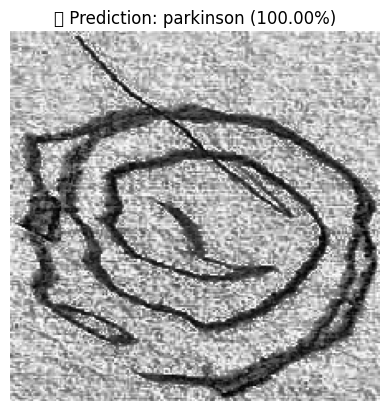

🧠 Predicted Class: parkinson
📊 Confidence: 100.00%


In [9]:
# Manual Prediction 

# ✅ Load Trained Model
model = load_model("F1_spiral_mobilenetv2_finetuned.h5")

# 🔁 Class Labels Mapping (Edit if your classes are named differently)
class_names = ['healthy', 'parkinson']  # class_indices from flow_from_directory order

# ✅ Load and Preprocess the Test Image
img_path = r"G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\test\spiral\parkinson\Parkinson1  (20).jpg"  # replace with your spiral image path

img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0  # Normalize [0, 1]
img_array = np.expand_dims(img_array, axis=0)  # Shape: (1, 224, 224, 3)

# 🧠 Predict
prediction = model.predict(img_array)
predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

# ✅ Show Image & Result
plt.imshow(img)
plt.axis('off')
plt.title(f"🧠 Prediction: {predicted_class} ({confidence:.2f}%)")
plt.show()

# Also print
print(f"🧠 Predicted Class: {predicted_class}")
print(f"📊 Confidence: {confidence:.2f}%")

167/167 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step
📋 Classification Report:
              precision    recall  f1-score   support

     healthy       0.84      1.00      0.92        76
   parkinson       1.00      0.85      0.92        91

    accuracy                           0.92       167
   macro avg       0.92      0.92      0.92       167
weighted avg       0.93      0.92      0.92       167



C:\Users\Python1\anaconda3\envs\vtpml04_2\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


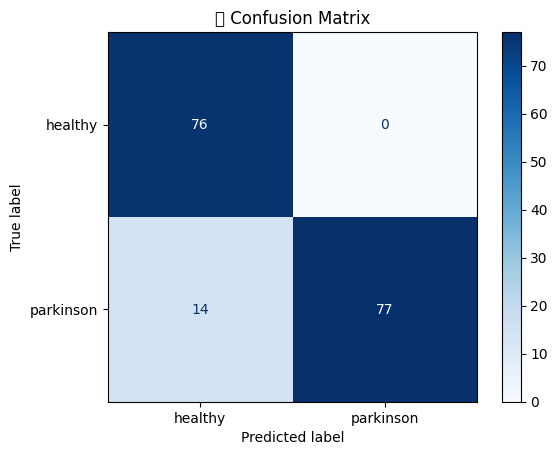

In [10]:
#Evaluate Model with Confusion Matrix & Classification Report
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 🧪 Predict on all test images
y_pred_probs = model.predict(test_gen)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes  # True labels from generator

# ✅ Classification Report
print("📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# 🔍 Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')
plt.title("🧠 Confusion Matrix")
plt.show()

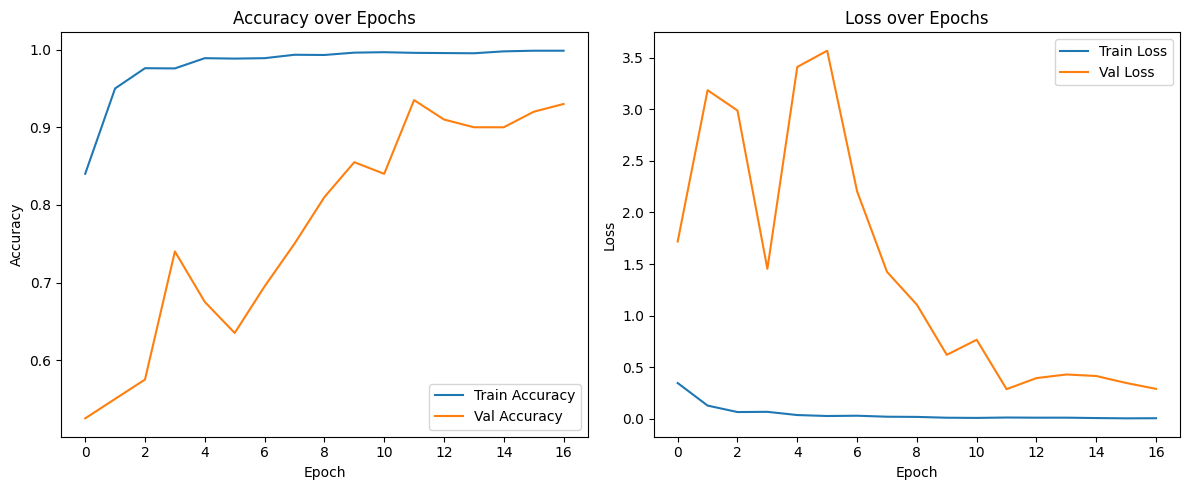

In [11]:
# Plot Accuracy & Loss Curves
# 📈 Training Accuracy & Loss Curves
plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()